In [ ]:
ALLOW_DOWNLOADS = False

def download_with_permission(operation, *args, **kwargs):
    if not ALLOW_DOWNLOADS:
        raise RuntimeError("Для загрузки ресурсов установите ALLOW_DOWNLOADS = True; пути к данным описаны в INPUTS.md.")
    return operation(*args, **kwargs)


# 

# Машинное обучение. ВМК МГУ

# Практическое задание 4: Анализ данных и обработка категориальных признаков

## Уровень: <font color='SkyBlue'>**Базовый (Base)**</font>

# О формате сдачи

🔷 **<font color='plum'>При решении ноутбука используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, обычно помечаются фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличе работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, обычно помечаются фразами Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Обычно выводы подразумевают под собой текстовый ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

-----------
<font color="white" style="opacity:0.2025"></font>







# Подготовка рабочей среды

Сначала установим нужные нам версии библиотек. Мы гарантируем, что в данных версиях задание будет корректно отрабатывать.

После установки нужных версий, **возможно,** нужно перезагрузить среду (runtime), но скорее всего вам это не понадобится


На скачивание файла и установку понадобится не более 5 минут.

<font color='OrangeRed'>**Важно!**</font>

Устанавливать нужные версии нужно каждый раз, когда создается новый рантайм. Например, если вы 2 часа подряд делаете это задание, то подготовить библиотеки достаточно 1 раз. Но если вы, например, начали в понедельник, затем закрыли/выключили ноутбук, то при продолжении в среду, вам нужно будет запустить рантайм заново и следовательно заново установить библиотеки.

<font color='OrangeRed'>**Важно!**</font>
Если вы предпочитаете делать практические задания на своем личном ноутбуке, то проверьте, что вы установили рабочее окружение в [соответствии с гайдом](https://github.com/MSU-ML-COURSE/ML-COURSE-24-25/blob/main/tutorials/%D0%A2%D1%83%D1%82%D0%BE%D1%80%D0%B8%D0%B0%D0%BB%20%D0%BF%D0%BE%20%D1%83%D1%81%D1%82%D0%B0%D0%BD%D0%BE%D0%B2%D0%BA%D0%B5%20%D1%80%D0%B0%D0%B1%D0%BE%D1%87%D0%B5%D0%B3%D0%BE%20%D0%BE%D0%BA%D1%80%D1%83%D0%B6%D0%B5%D0%BD%D0%B8%D1%8F%20%D0%B2%20Python%20%D0%B4%D0%BB%D1%8F%20%D1%80%D0%B5%D1%88%D0%B5%D0%BD%D0%B8%D1%8F%20%D0%B7%D0%B0%D0%B4%D0%B0%D1%87%20(2).pdf)

In [ ]:
# Установка зависимостей выполняется отдельно по requirements.txt.
# Установка зависимостей выполняется отдельно по requirements.txt.


Проверим версию библиотеки:

In [ ]:
import catboost
assert(catboost.__version__ == '1.2.8')

Теперь можно приступать к выполнению задания! :)

-----------
<font color="white" style="opacity:0.2025"></font>

# Часть 1. Анализ и обработка данных

В прошлом ноутбуке мы познакомились, как можно вызывать методы машинного обучения с помощью библиотеки `sklearn`. Казалось бы, бери самые передовые методы машинного обучения (да и нейросетей), применяй на данные, и радуйся жизни. Но на самом деле, на качество решения задачи влияет не столько вид модели, а то, какие данные мы подаем этой модели.

В реальном мире данные редко бывают безупречными. Они могут включать ошибки ввода, неточности, пропуски и выбросы, что часто происходит из-за человеческих ошибок или нехватки информации. Если не провести предварительную обработку данных, это может негативно сказаться на качестве модели машинного обучения. Поэтому важно уделять внимание анализу и обработке данных перед их использованием.

 При правильном анализе и обработке датасета есть возможность сильно забустить качество, даже сильнее, чем если бы мы взяли какую-то более "мощную" модель машинного обучения.

В данном секции мы разберем основные приемы, которые могут приняться при анализе и обработке данных - этапе, который производится перед подачей данных в саму модель и ее обучении.

## Работа с данными



Будем работать с датасетом [описания квартир на Airbnb](https://www.kaggle.com/datasets/arianazmoudeh/airbnbopendata/data)

Мы уже скачали его за вас:

In [ ]:
import gdown

download_with_permission(gdown.download, id='1GKaJXuZm74Bs5b9FCxUrbcZAoLTaN5MT')

Работать с данными будем, как и раньше, через `pandas` + `numpy`

In [ ]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None) # установим настройку, чтобы всегда отображались все столбцы

In [ ]:
data = pd.read_csv("data/Airbnb_Open_Data.csv", low_memory=False)

Посмотрим на все данные:

In [ ]:
data.head()

Только на вещественные признаки:

In [ ]:
data.describe()

Только на категориальные и текстовые:

In [ ]:
data.describe(include="object")

<font color='LightSteelBlue'>**Пояснение:**</font> Здесь можно увидеть, что некоторые вещественные данные на самом деле хорошо бы считать категориальными (например `id`), а некоторые категориальные - вещественными (наприер, `price`). Данные наблюдения как раз относятся к анализу данных - если поправить тип данных, то можно потенциально улучшить качество модели

### <font color='DarkOrange'>**Задание 1 [1 балл]**</font>

1) <font color='DarkOrange'>**[0.5 баллa]:**</font>  Какие еще категориальные и текстовые признаки из датасета на самом деле нужно считать вещественными?

2) <font color='DarkOrange'>**[0.5 баллa]:**</font>  Какие еще вещественные признаки из датасета на самом деле нужно считать категориальными или текстовыми?

В каждом пункте приведите хотя бы по 1 примеру

<font color='MediumOrchid'>**Ваш ответ тут:**</font><br>
1) Service fee надо бы считать вещественным признаком <br>
2) Host id по-хорошему должен быть категориальным, construction year тоже. <br>

---

### Работа с пропусками в вещественных данных

Но пока не будем это все исправлять: углубимся, как можно работать с пропусками в данных: не все модели хорошо умеют обучаться с пропусками в данных, а также их нивелирование может привести к улучшению качества обучаемых моделей

<font color='MediumTurquoise'>**Tip:**</font> Пропуски в данных для машинного обучения могут возникать из-за ошибок при сборе данных, например, из-за сбоев оборудования или человеческого фактора. Также они могут появляться в результате отсутствия информации, когда респонденты не отвечают на определенные вопросы в опросах или анкетах. Наконец, пропуски могут быть следствием фильтрации данных, когда некоторые записи удаляются из-за несоответствия критериям качества.

В поиске пропущенных значений нам поможет функция info:

In [ ]:
data.info()

In [ ]:
data.shape

#### <font color='DarkOrange'>**Задание 2 [0.5 баллa]**</font>

В скольких столбцах есть хотя бы 1 пропуск?

Можно вывести решение как программно, так и визуально

In [ ]:
# your code here
columns_with_nan = data.isna().any()
lst_nan_col = data.columns[columns_with_nan].to_list()
print(lst_nan_col)

<font color='MediumOrchid'>**Ваш ответ тут:**</font><br>
'NAME', 'host_identity_verified', 'host name', 'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country', 'country code', 'instant_bookable', 'cancellation_policy', 'Construction year', 'price', 'service fee', 'minimum nights', 'number of reviews', 'last review', 'reviews per month', 'review rate number', 'calculated host listings count', 'availability 365', 'house_rules', 'license'


#### <font color='DarkOrange'>**Задание 3 [1 балл]**</font>

На основе пропусков, какой бы вы 1 столбец выкинули из данных как совсем неинформативный?

<font color='MediumOrchid'>**Ваш ответ тут:**</font><br>
Столбец license. 2 не NaN объекта это сильно.

----

<font color='plum'>**Подход 1**</font> Удаление объектов с пропусками

Метод немного из "пушки по воробьям", но может быть иногда полезен

Можно удалить все строки, где есть хотя бы 1 пропуск

In [ ]:
data_drop_rows = data.dropna(axis="index")

Или все столбцы:

In [ ]:
data_drop_columns = data.dropna(axis="columns")

Посмотрим на них:

In [ ]:
data_drop_rows.shape

In [ ]:
data_drop_rows.info()

In [ ]:
data_drop_columns.shape

In [ ]:
data_drop_columns.info()

#### <font color='DarkOrange'>**Задание 4 [2 баллa]**</font>

1) <font color='DarkOrange'>**[1 балл]**</font> Какие проблемы вы видите в подходе удаления строк с пропусками, основываясь на значении data_drop_rows?

2) <font color='DarkOrange'>**[1 балл]**</font> Какие проблемы вы видите в подходе удаления столбцов с пропусками, основываясь на значении data_drop_columns?

<font color='MediumOrchid'>**Ваши выводы тут:**</font><br>
1) Мы уничтожили буквально всю таблицу и оставили всего 1 строку. Подход радикальный: можно вообще остаться без каких-либо записей, или уничтожить большую их часть.
2) У нас осталось 3 аттрибута из 26. Видно, что и такой подход радикален, поскольку можно даже за 1 NaN полностью потерять 1 из признаков, который может быть довольно важным. Тоже теряем огромную часть данных.

---

<font color='plum'>**Подход 2**</font> Замена на число


Можно заменить на конкретное число/среднее по столбцу/медиану по столбцу итд:

In [ ]:
data_number = data.select_dtypes('number') # выберем только вещественные признаки

In [ ]:
data_number.head()

In [ ]:
tmp = data_number.fillna(0) # на 0

In [ ]:
tmp.head() # Обратите внимание на изменение 2й строки в столбце reviews per month

In [ ]:
tmp.info()

In [ ]:
tmp = data_number.fillna(data_number.mean()) # Обратите внимание на изменение 2й строки в столбце reviews per month
tmp.head()

In [ ]:
tmp.info()

#### <font color='DarkOrange'>**Задание 5 [0.5 баллa]**</font>

По аналогии с предыдущим кодом, замените пропуски на медианы по столбцам

In [ ]:
# your code here
tmp_2 = data_number.fillna(data_number.median())
tmp_2.head() # Смотрим на reviews per month

In [ ]:
tmp_2.info()

#### <font color='DarkOrange'>**Задание 6 [1 балл]**</font>

В чем основное преимущество замены на медиану по сравнению со средним с точки зрения анализа выбросов (аномальных значений)?

<font color='MediumOrchid'>**Ваши выводы тут:**</font><br>
Среднее арифметическое очень чувствительно к выбросам: если у нас есть какое-то аномально огромное значение в выборке, то это всё пойдёт в расчёт среднего и сильно изменит результат.<br><br>
Медиана намного более устойчива тем, что она выбирается как элемент посередине отсортированной выборки (в нечётном случае ровно выбирается середина, в чётном - среднее двух элементов посередине), и таким образом наличие выбросов сильно значение медианы не меняет.

### Работа с пропусками в категориальных признаках


In [ ]:
data_object = data.select_dtypes('object') # выберем невещественные значения

In [ ]:
data_object.head()

<font color='plum'>**Подход 1**</font> Замена на определенную новую категорию


In [ ]:
tmp = data_object.fillna("other") # обратите внимание на столбец house_rules в 4й строке
tmp.head()

In [ ]:
tmp.info()

<font color='plum'>**Подход 2**</font> Замена на самую частую категорию по столбцам

In [ ]:
tmp = data_object.fillna(data_object.mode().iloc[0])
tmp.head()

In [ ]:
tmp.info()

-------

### Работа с дублями

Иногда необходимо удалять дубли из данных, так как несколько одинаковых объектов не всегда указывают на их большую значимость для алгоритма. Дубли могут возникать также из-за ошибок ввода.

In [ ]:
data_geo = data[["lat", "long"]].copy()
data_geo

In [ ]:
data_geo.drop_duplicates()

### Работа с вещественными выбросами (аномалиями)

Каждый признак в данных имеет свое распределение, которое описывает, как значения этого признака распределены по всему набору данных. Одним из способов выявления аномалий является использование интерквартильного размаха (IQR), который показывает диапазон значений между первым (Q1) и третьим квартилями (Q3).

$$IQR = Q_3 - Q_1$$

где $Q_1$ — первая квартиль — такое значение признака, меньше которого ровно 25% всех значений признаков. $Q_3$ — третья квартиль — значение, меньше которого ровно 75% всех значений признака.


Аномалии могут быть определены как значения, выходящие за пределы диапазона

$$[Q1 - 1.5 * IQR, Q3 + 1.5 * IQR]$$

 Такой подход позволяет эффективно находить выбросы, которые могут искажать анализ данных. Использование IQR помогает улучшить качество модели и повысить ее точность, исключая ненадежные данные.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set()

В отображение графика box_plot (коробка с усами) уже входит отображение точек, выходящие за интерквартильный размах - в данном случает они выглядят как крулгые точки

In [ ]:
data_new = data.select_dtypes('number').drop(["id", "host id"], axis=1)
sns.boxplot(data_new)
plt.xticks(rotation=45, ha='right')
plt.show()

In [ ]:
quantiles = data_new.quantile([0.25, 0.75])
quantiles

#### <font color='DarkOrange'>**Задание 7 [1 балл]**</font>

Посчитайте интерквартильный размах для всех признаков из `data_new`, удалите выбросы из `data_new` по предложенному правилу и отобразите новый очищенный датафрейм на аналогичном box_plot графике

In [ ]:
# your code here
quantiles_t = quantiles.transpose()
iqr = quantiles_t[0.75] - quantiles_t[0.25]

ok_range_left = quantiles_t[0.25] - 1.5 * iqr # Левая граница
ok_range_left = ok_range_left.transpose()

ok_range_right = quantiles_t[0.75] + 1.5 * iqr # Правая граница
ok_range_right = ok_range_right.transpose()

# Для каждой строчки делаем проверку по столбцам

data_without_anomalies = data_new[((data_new >= ok_range_left) & (data_new <= ok_range_right)).all(axis=1)]
data_without_anomalies.info()

In [ ]:
print(data_new.info()) # Что было до изменений

In [ ]:
sns.boxplot(data_without_anomalies)
plt.xticks(rotation=45, ha='right')
plt.show()

#### <font color='DarkOrange'>**Задание 8 [1 балл]**</font>

Почему на получившемся графике все еще отображаются точки (аномалии)?

<font color='MediumOrchid'>**Ваши выводы тут:**</font><br>
По той причине, что в уже обновлённном датасете сдвинулись квантили.<br>
Соответственно это новые числа в IQR, совершенно другой диапазон "неаномальных" значений.

### Работа с категориальными выбросами (аномалиями)

Анализ встречаемости категориальных признаков позволяет выявить категории с низкой частотой. Их можно объединить, что ускорит обучение алгоритмов и может улучшить качество модели. Этот подход также помогает обнаружить битые данные, о чем мы поговорим далее.

In [ ]:
data_new = data.select_dtypes('object')
value_counts = data_new["neighbourhood group"].value_counts(ascending=False)
value_counts

Например, в признаке `neighbourhood group` всего 2 выделяющихся значений: их можно как и записать в категорию `other`, так и в целом удалить из данных

In [ ]:
column_name = "neighbourhood group"
data_new[data_new[column_name].isin(value_counts[value_counts <= 100].index)] = "other"
data_new["neighbourhood group"].value_counts(ascending=False)

---

# Часть 2. Обработка категориальных признаков

Перед работой с данными сделаем небольшую работу над ними:

In [ ]:
def parse_price(x):
    try:
        return float(x[1:])
    except:
        return None

In [ ]:
data

In [ ]:
data['price_value'] = data['price'].apply(lambda x: parse_price(x))
data['service_fee_value'] = data['service fee'].apply(lambda x: parse_price(x))
data_cleared = data.dropna(subset=['price_value', 'service_fee_value'], axis=0)
data_cleared = data_cleared.drop(['price', 'id', 'host id', 'service fee'], axis=1)
data_cleared

Заменим все пропуски в вещественных признаках на среднее:

In [ ]:
number_columns = data_cleared.select_dtypes(include=['number']).columns

data_cleared[number_columns] = data_cleared[number_columns].fillna(data_cleared[number_columns].mean())

Пусть целевое значение, которое мы хотим предсказать - это `price`. Все остальное - признаки.

Выделим обучающую и тестовую выборки:

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(data_cleared.drop('price_value', axis=1), data_cleared[['price_value']], test_size=0.2)

In [ ]:
X_train

Чуть позже будем пытаться обучить knn-регрессор.

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

# не забываем сделать нормировку, так как метод метрический

X_train_number = np.array(X_train.select_dtypes('number'))
X_test_number = np.array(X_test.select_dtypes('number'))

scaler = MinMaxScaler()
scaler.fit(X_train_number)

X_train_number_scaled = scaler.transform(X_train_number)
X_test_number_scaled = scaler.transform(X_test_number)

Одним из способов переводить категориальные признаки в численное представления является <font color='CornflowerBlue'>**One-Hot Encoding (OHE).**</font>

Это метод кодирования категориальных признаков, который преобразует каждую категорию в отдельный бинарный вектор. Для каждой уникальной категории создается новая колонка, где значение 1 указывает на присутствие данной категории, а 0 — на ее отсутствие. Например, если у нас есть признак "Цвет" с категориями "Красный", "Зеленый" и "Синий", OHE создаст три новых колонки: "ЦветКрасный", "ЦветЗеленый" и "ЦветСиний". Это позволяет алгоритмам машинного обучения лучше воспринимать категориальные данные, так как они не могут обрабатывать текстовые значения напрямую.

<font color='OrangeRed'>**Примечание**</font> Однако стоит помнить, что OHE может привести к увеличению размерности данных, особенно при наличии большого количества категорий.

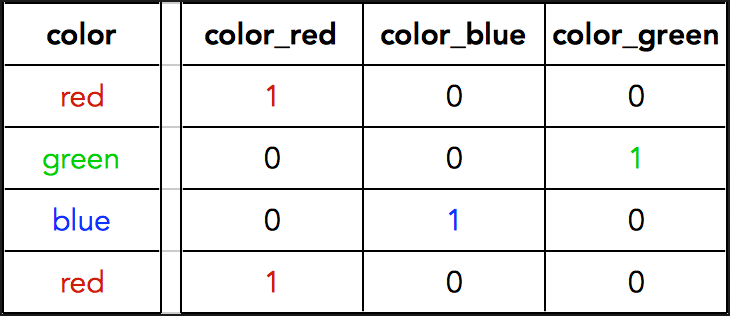

Существует два наиболее используемых способа применения данного алгоритма:

1) Через метод `pandas.get_dummies`

2) Через трансформер в `sklearn` `OneHotEncoder`

Давайте закодируем несколько признаков с помощью OHE и посмотрим, как обучать модель:

In [ ]:
from sklearn.preprocessing import OneHotEncoder

columns = ["host_identity_verified", "neighbourhood group", "room type", "cancellation_policy"]

enc = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
# sparse_output - ставим такой параметр, чтобы вернулась обычная матрица
# handle_unknown - не будет падать из-за ошибок
enc.fit(X_train[columns])

train_neighbourhood_group_ohe = enc.transform(X_train[columns])
test_neighbourhood_group_ohe = enc.transform(X_test[columns])

Посмотрим, на сколько увеличилось число признаков:

In [ ]:
print(train_neighbourhood_group_ohe.shape)
print(enc.get_feature_names_out(columns))

Составим новый датасет:

In [ ]:
X_train_new = np.hstack((X_train_number_scaled, train_neighbourhood_group_ohe))
X_test_new = np.hstack((X_test_number_scaled, test_neighbourhood_group_ohe))

In [ ]:
regr = KNeighborsRegressor(n_neighbors=5)

regr.fit(X_train_new, np.array(y_train))

In [ ]:
mean_squared_error(regr.predict(X_test_new), np.array(y_test)) # может работать несколько секунд

### <font color='DarkOrange'>**Задание 9 [2 баллa]**</font>

Изучите, как работает метод [pandas.get_dummies](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.get_dummies.html) и проделайте аналогичную операцию кодирования, используя только его

Покажите, что модель с такими же признаки тоже обучается и выдает примерно такое же качество

In [ ]:
#  your code here
train_neighbourhood_group_ohe = pd.get_dummies(X_train[columns], dummy_na = True)
test_neighbourhood_group_ohe = pd.get_dummies(X_test[columns], dummy_na = True)

test_neighbourhood_group_ohe = test_neighbourhood_group_ohe.reindex(
    columns=train_neighbourhood_group_ohe.columns, fill_value = 0)
# Вот это OneHotEncodder делает через handle_unknown = 'ignore'
# Заполняем неизвестные для test столбцы нулями ну и всё перегруппировываем
# Если мы это не сделаем, будет возникать ошибка. А так я воссоздаю по сути OneHotEncodder


# Далее всё по-старинке
X_train_new = np.hstack((X_train_number_scaled, train_neighbourhood_group_ohe))
X_test_new = np.hstack((X_test_number_scaled, test_neighbourhood_group_ohe))

regr = KNeighborsRegressor(n_neighbors=5)

regr.fit(X_train_new, np.array(y_train))


In [ ]:
mean_squared_error(regr.predict(X_test_new), np.array(y_test)) # может работать несколько
# Результат ровно тот же получается :)

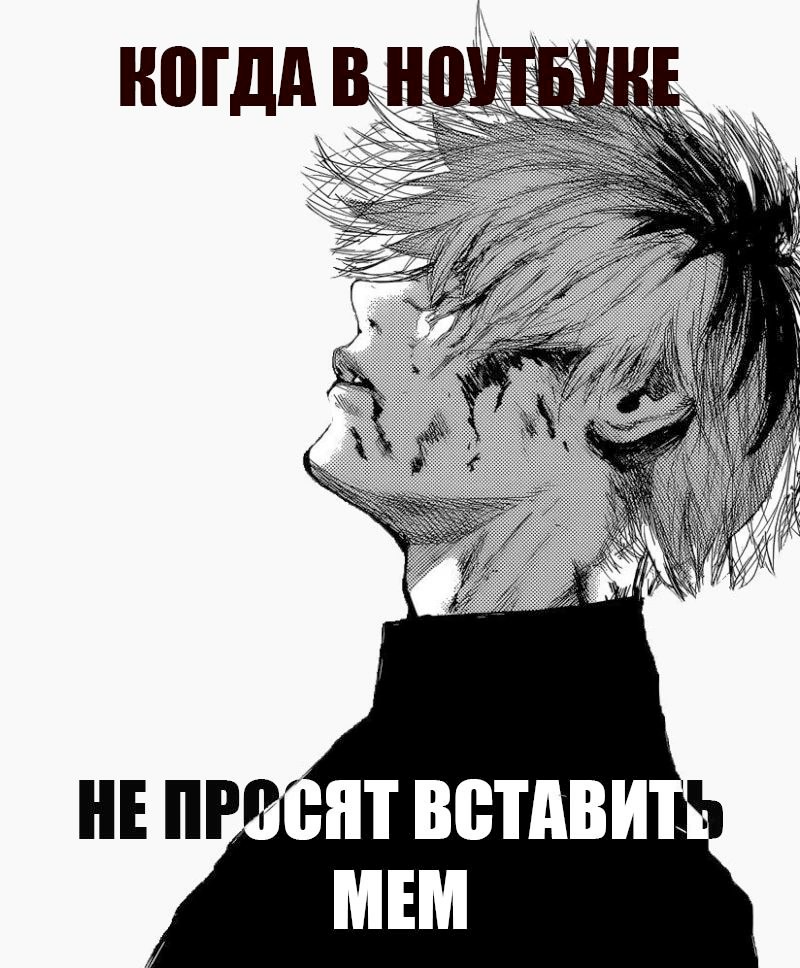